In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import pandas as pd

plt.rcParams['text.usetex'] = True
plt.rcParams.update({'font.size': 25})

1. naloga: model epidemije

In [2]:
def zamenjava(x):
    '''zamenja negativne vrednosti v 0, za prikaz'''
    rez = []
    for seznam in x:
        for i in seznam:
            if i < 0:
                seznam[np.where(seznam == i)] = 0
        rez.append(seznam)
    return rez
def okužba(y, x, alpha):#en1
    d, b, i = y
    return [-alpha*d*b, alpha*d*b, 0]
def epidemija_imunost(y, x, R):#en2
    d, b, i = y
    return [-R*d*b, R*d*b - b, b]
def epidemija_ozdravitev(y,x,R):#en3
    d,b,i = y
    return [-R*d*b + b, R*d*b - b, 0]
def ozdravitev_bolje(y, x, R, I):#en4
    d,b,i = y
    return [-R*d*b + I*i, R*d*b - b, b - I*i]

vrh epidemije 61.7 %, pri brezdimenzijskem času 0.032
skupno število obolelih 99


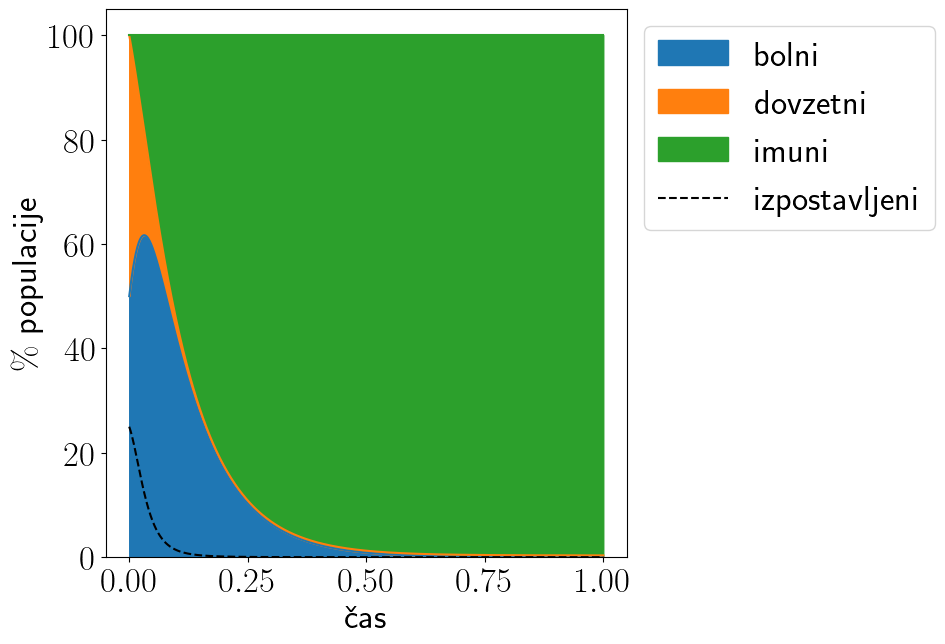

In [13]:
initial_conditions = [0.5, 0.5, 0.0]
x_values = np.linspace(0, 10, 1000)
R0 = 5 #reprodukcijsko število
I0 = 1 #razm imunosti

#result = odeint(okužba, initial_conditions, x_values, args=(R0,)) #R0 = alpha
result = odeint(epidemija_imunost, initial_conditions, x_values, args=(R0,))
# result = odeint(epidemija_ozdravitev, initial_conditions, x_values, args=(R0,))
# result = odeint(ozdravitev_bolje, initial_conditions, x_values, args=(R0,I0))
D_solution, B_solution, I_solution = result.T
X = [i / x_values[-1] for i in x_values] #normiran čas

D, B, I = zamenjava([D_solution, B_solution, I_solution])
lega_max = np.where(B == max(B))[0][0]
print(f'vrh epidemije {round(100*B[lega_max],1)} %, pri brezdimenzijskem času {round(X[lega_max],3)}')
print(f'skupno število obolelih {int(sum(B))}')
df = pd.DataFrame({
    'bolni': B*100,
    'dovzetni' : D*100,
    'imuni': I*100
}, index=X)
ax = df.plot.area(figsize=(10,7))
ax.set_xlabel('čas')
ax.set_ylabel('$\%$ populacije')
plt.plot(X, 100*D_solution*B_solution, 'k--', label='izpostavljeni')
#ax.legend(bbox_to_anchor=(0.5, 1.2), loc='upper center', ncol=5)
ax.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
#plt.savefig(f'slike/ozdravitev_R{R0}_I{I0}.pdf')
#plt.savefig('slike/ozdravitev.pdf')
#plt.show()

plt.plot(X, D_solution, label='dovzetni')
plt.plot(X, B_solution, label='bolni')
plt.plot(X, I_solution, label='imuni')
plt.plot(X, D_solution*B_solution, 'k--',label='izpostavljeni')
plt.legend()
plt.xlabel('čas')
plt.ylabel('populacija')
plt.tight_layout()
plt.show()

upoštevanje smrti

vrh epidemije 17.1 %, pri brezdimenzijskem času 0.254
skupno število obolelih 38


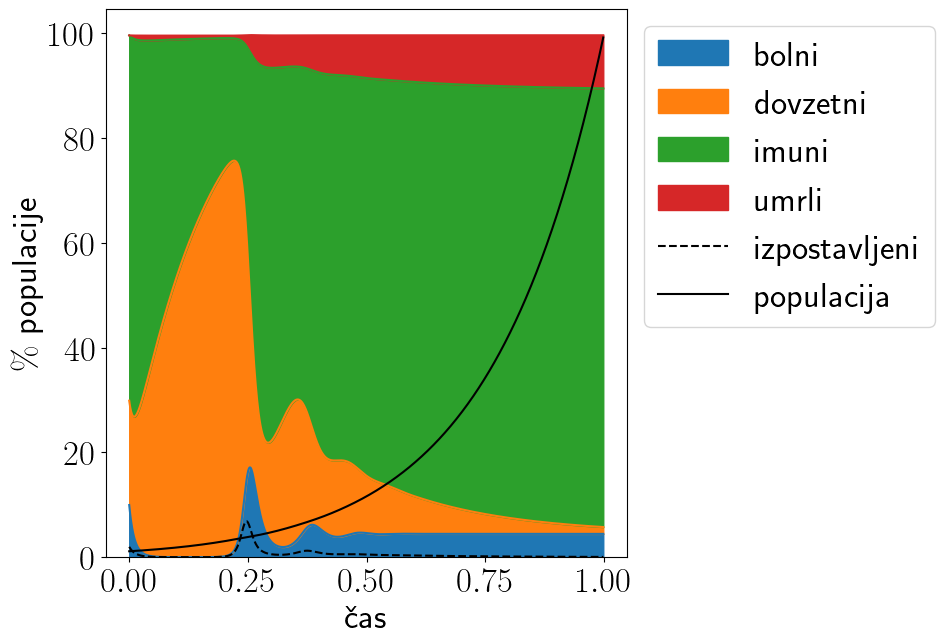

In [5]:
def epidemija_rojstva_smrti(y,x,R,I,M=0, N=0):#rojstva+smrti
    d,b,i,m = y
    return [-R*d*b + I*i + N*(d+i), R*d*b - b - M*b, b - I*i, M*b]
def epidemija_smrti(y,x,R,I,M=0, N=0):#le smrti
    d,b,i,m = y
    return [-R*d*b + I*i, R*d*b - b - M*b, b - I*i, M*b]
def normiranje(D,B,I,M,X):
    for i in range(len(D)-1):
        D[i] = D[i] / (D[i+1]+B[i+1]+I[i+1]+M[i+1])
        B[i] = B[i] / (D[i+1]+B[i+1]+I[i+1]+M[i+1])
        I[i] = I[i] / (D[i+1]+B[i+1]+I[i+1]+M[i+1])
        M[i] = M[i] / (D[i+1]+B[i+1]+I[i+1]+M[i+1])
    return [D[:-2],B[:-2],I[:-2],M[:-2],X[:-2]]

initial_conditions = [0.2, 0.1, 0.7, 0.0]
x_values = np.linspace(0, 100, 1000)
R = 1
I = 0.01
M = 0.1
N = 0.05

result = odeint(epidemija_smrti, initial_conditions, x_values, args=(R, I, M, N))
result = odeint(epidemija_rojstva_smrti, initial_conditions, x_values, args=(R, I, M, N))
D_solution, B_solution, I_solution, M_solution = result.T
X = [i / x_values[-1] for i in x_values] #normiran čas

D, B, I, M = zamenjava([D_solution, B_solution, I_solution, M_solution])
pop = 100*(B+D+I+M)
D,B,I,M,X = normiranje(D,B,I,M,X)
df = pd.DataFrame({
    'bolni': B*100,
    'dovzetni' : D*100,
    'imuni': I*100,
    'umrli': M*100
}, index=X)
lega_max = np.where(B == max(B))[0][0]
print(f'vrh epidemije {round(100*B[lega_max],1)} %, pri brezdimenzijskem času {round(X[lega_max],3)}')
print(f'skupno število obolelih {int(sum(B))}')
ax = df.plot.area(figsize=(10,7))
ax.plot(X, 100*D*B, 'k--', label='izpostavljeni')
ax.plot(X, 100 * (pop[:-2]/pop[-1]) , 'k', label='populacija')
ax.set_xlabel('čas')
ax.set_ylabel('$\%$ populacije')
ax.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
#plt.savefig('slike/smrti_rojstva_zanimivo.pdf')
plt.show()

odvisnosti

In [6]:
initial_conditions_smrt = [0.2, 0.1, 0.7, 0.0]
initial_conditions_ozdr = [0.5, 0.5, 0.0]
x_values = np.linspace(0, 10, 1000)
X = [i / x_values[-1] for i in x_values] #normiran čas
R = 1
I = 0.01
I0 = 1
M = 0.1
N = 0.05

variacije = [i for i in range(1,100)]
smrti = pd.DataFrame(columns = ['vrh','čas_vrh', 'št obolelih'])
ozdravitev = pd.DataFrame(columns = ['vrh','čas_vrh', 'št obolelih'])
R_data = []
I_data = []
preceplenost_data = []
zač_okuženi_data = []
vrh_data = [[],[]]
vrh_čas_data = [[],[]]
št_obol_data = [[],[]]
for i in variacije:
    R = i
    I0 = 1
    R_data.append(R)
    result = odeint(ozdravitev_bolje, initial_conditions_ozdr, x_values, args=(R, I0))
    D_solution, B_solution, I_solution = result.T
    lega_max = np.where(B_solution == max(B_solution))[0][0]
    vrh_data[0].append(B_solution[lega_max])
    vrh_čas_data[0].append(X[lega_max])
    št_obol_data[0].append(int(sum(B_solution)))

    R = 1
    I0 = i
    D_solution, B_solution, I_solution = odeint(ozdravitev_bolje, initial_conditions_ozdr, x_values, args=(R,I0)).T
    lega_max = np.where(B_solution == max(B_solution))[0][0]
    vrh_data[1].append(B_solution[lega_max])
    vrh_čas_data[1].append(X[lega_max])
    št_obol_data[1].append(int(sum(B_solution)))

In [7]:
initial_conditions_smrt = [0.2, 0.1, 0.7, 0.0]
initial_conditions_ozdr = [0.5, 0.5, 0.0]
x_values = np.linspace(0, 10, 1000)
X = [i / x_values[-1] for i in x_values] #normiran čas
R = 1
I = 0.01
I0 = 1
M = 0.1
N = 0.05

variacije = [i/100 for i in range(1,100)]
smrti = pd.DataFrame(columns = ['vrh','čas_vrh', 'št obolelih'])
ozdravitev = pd.DataFrame(columns = ['vrh','čas_vrh', 'št obolelih'])
initial_data = []
preceplenost_data = []
vrh_data_pr = [[],[]]
vrh_čas_data_pr = [[],[]]
št_obol_data_pr = [[],[]]
for i in variacije:
    precepljeni = i
    initial_data.append(100*precepljeni)
    result = odeint(ozdravitev_bolje, [(1-precepljeni)/2, (1-precepljeni)/2, precepljeni], x_values, args=(R, I0))
    D_solution, B_solution, I_solution = result.T
    lega_max = np.where(B_solution == max(B_solution))[0][0]
    vrh_data_pr[0].append(B_solution[lega_max])
    vrh_čas_data_pr[0].append(X[lega_max])
    št_obol_data_pr[0].append(int(sum(B_solution)))

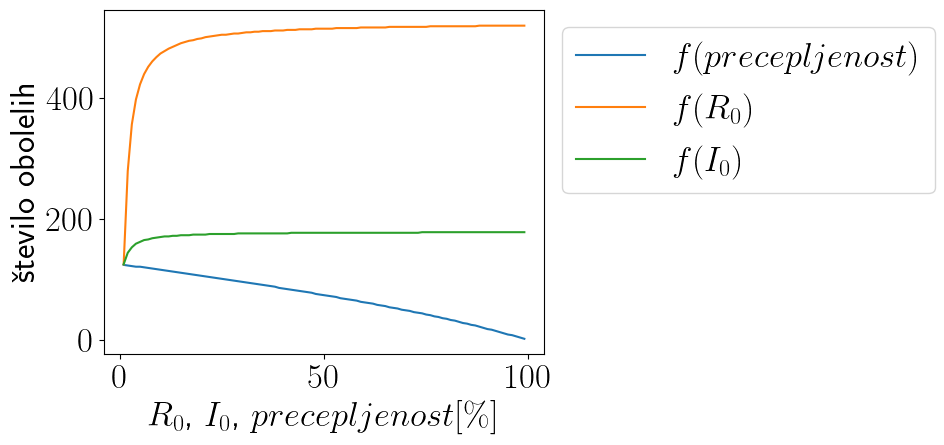

In [8]:
plt.figure(figsize=(10,5))
plt.plot(initial_data, št_obol_data_pr[0], label='$f(precepljenost)$')
plt.plot(np.array(R_data), št_obol_data[0], label='$f(R_0)$')
plt.plot(np.array(R_data), št_obol_data[1], label='$f(I_0)$')
plt.xlabel('$R_0$, $I_0$, $precepljenost[\%]$')
plt.ylabel('število obolelih')
plt.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
#plt.savefig('slike/št_obolelih_odvisnost.pdf')

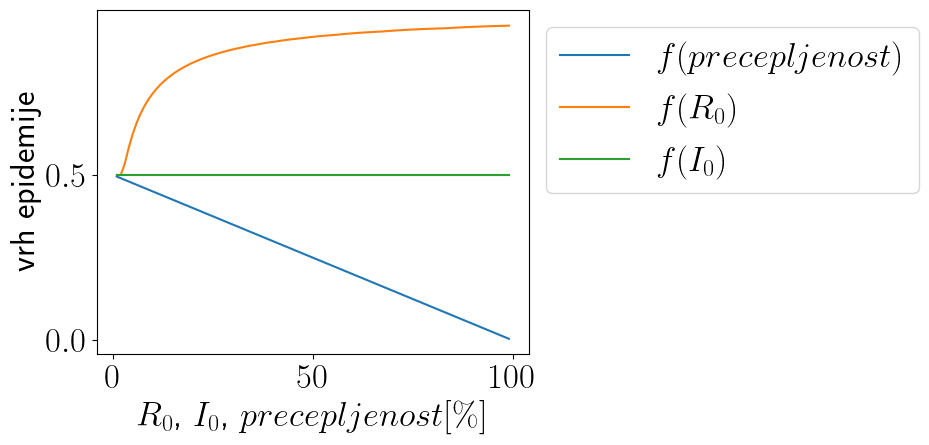

In [9]:
plt.figure(figsize=(10,5))
plt.plot(initial_data, vrh_data_pr[0], label='$f(precepljenost)$')
plt.plot(np.array(R_data), vrh_data[0], label='$f(R_0)$')
plt.plot(np.array(R_data), vrh_data[1], label='$f(I_0)$')
plt.xlabel('$R_0$, $I_0$, $precepljenost[\%]$')
plt.ylabel('vrh epidemije')
plt.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
#plt.savefig('slike/vrh_odvisnost.pdf')

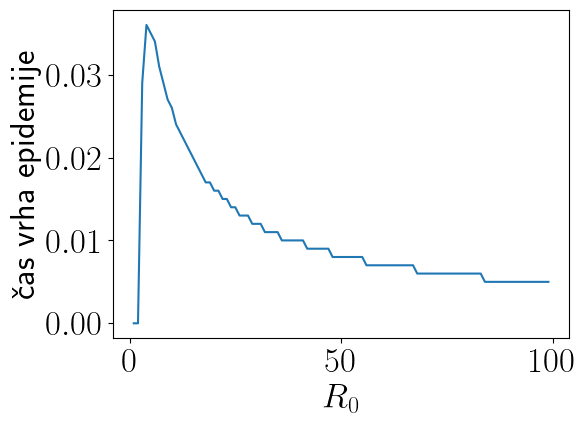

In [10]:
#plt.figure(figsize=(10,5))
#plt.plot(initial_data, vrh_čas_data_pr[0], label='$f(precepljenost)$')
plt.plot(np.array(R_data), vrh_čas_data[0], label='$f(R_0)$')
#plt.plot(np.array(R_data)/max(R_data), vrh_čas_data[1], label='$f(I_0)$')
plt.xlabel('$R_0$')
plt.ylabel('čas vrha epidemije')
#plt.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
#plt.savefig('slike/čas_vrh_odvisnost.pdf')

In [36]:
def več_stadijev(y,x,alpha,beta1,beta2,beta3,gamma,M=0,N=0):
    d,b1,b2,b3,i,m = y
    return [-alpha*d*b1 + gamma*i + N*(d+i), alpha*d*b1 - beta1*b1 - M*b1, 
            beta1*b1 - beta2*b2 - M*b2, beta2*b2 - beta3*b3 - M*b3, 
            beta3*b3 - gamma*i, M*b1+M*b2+M*b3]

vrh epidemije 31.9 %, pri brezdimenzijskem času 0.133
skupno število obolelih 1082


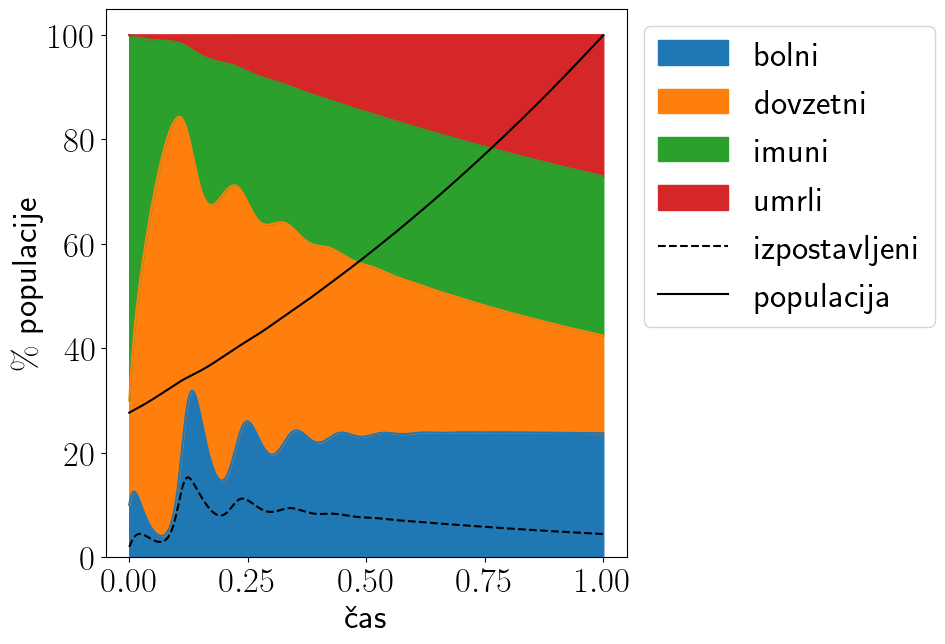

In [90]:
initial_conditions = [0.2, 0.1, 0.,0, 0.7, 0.0]
x_values = np.linspace(0, 200, 5000)
alpha = 1.5
beta1 = 1
beta2 = 0.2
beta3 = 0.8
gamma = 0.1
M = 0.01
N = 0.01

result = odeint(več_stadijev, initial_conditions, x_values, args=(alpha, beta1, beta2, beta3, gamma, M, N))
D_solution, B1_solution, B2_solution, B3_solution, I_solution, M_solution = result.T
X = [i / x_values[-1] for i in x_values] #normiran čas

B_solution = B1_solution+B2_solution+B3_solution
D, B, I, M = zamenjava([D_solution, B_solution, I_solution, M_solution])
pop = 100*(B+D+I+M)
D,B,I,M,X = normiranje(D,B,I,M,X)
df = pd.DataFrame({
    'bolni': B*100,
    'dovzetni' : D*100,
    'imuni': I*100,
    'umrli': M*100
}, index=X)
lega_max = np.where(B == max(B))[0][0]
print(f'vrh epidemije {round(100*B[lega_max],1)} %, pri brezdimenzijskem času {round(X[lega_max],3)}')
print(f'skupno število obolelih {int(sum(B))}')
ax = df.plot.area(figsize=(10,7))
ax.plot(X, 100*D*B, 'k--', label='izpostavljeni')
ax.plot(X, 100 * (pop[:-2]/pop[-1]) , 'k', label='populacija')
ax.set_xlabel('čas')
ax.set_ylabel('$\%$ populacije')
ax.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
#plt.savefig('slike/stadiji.pdf')
plt.show()